## 目前處理方式

1. **篩選 `select_memo = 15_納入統計人數`，依癌別及診斷年度整理個案。**
2. **計算 KM 存活率與生命表，依存活率模組提供的官方年齡權重計算標準化存活率。**

診斷年度：一般癌別民國 108–112、子宮頸 110–112、胰臟 111–112；肝癌 BCLC 與子宮頸／子宮體／卵巢 FIGO 取 108–112。追蹤不滿五年者不外推，無法計算的期別以「—」呈現、不填 0。

### 本版修正說明（相對舊版）

1. **年齡權重**：改用官方全國標準人口權重（非本院個案比例）。
2. **診斷年區間**：分癌別處理，非統一 108–112。
3. **零個案期別**：顯示「—」，不填 0。
4. **KM 不外推**：追蹤不足回空值，曲線不延伸至 5 年。
5. **第IV期 M0/M1**：僅頭頸癌細分，不對無 M 分期癌別切分。

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from docx import Document
from lifelines import KaplanMeierFitter 

for f in ['Microsoft JhengHei','Microsoft YaHei','SimHei','Noto Sans CJK TC']:
    try:
        mpl.font_manager.findfont(f, fallback_to_default=False)
        mpl.rcParams['font.family'] = f; break
    except Exception:
        pass
mpl.rcParams['axes.unicode_minus'] = False

HERE = Path.cwd()
BASE = next(p for p in [HERE, *HERE.parents] if (p / '2026存活率個案清單.xlsx').exists())
CASE_FILE = BASE / '2026存活率個案清單.xlsx'
WORD_FILE = BASE / '1_115年癌症存活率回饋說明_2026092320261005090504.docx'
TRACKING_END = pd.Timestamp('2025-12-31') 
print('BASE =', BASE)

BASE = D:\YLH\CancerRegistry_System\Surviva


In [2]:
# 官方 102年全國各癌別標準人口權重（Word 回饋說明附表，欄序對應下列 17 癌別）
_doc = Document(str(WORD_FILE)); _tbl = _doc.tables[0]
CANCERS = ['Oral cavity','Oropharynx','Hypopharynx','Nasopharynx','Colon and Rectum','Liver',
           'Pancreas','Lung','Breast','Cervix','Esophagus','Stomach','Bladder','Corpus','Ovary','Prostate','Larynx']
WEIGHTS = {name: np.array([float(_tbl.cell(r, c).text.strip())/100 for r in range(2, 7)])
           for c, name in enumerate(CANCERS, start=2)}
assert all(abs(w.sum()-1) < 1e-9 for w in WEIGHTS.values()), '權重列非 15-44/45-54/55-64/65-74/75+'

def year_range(cancer):
    if cancer == 'Pancreas': return (111, 112)
    if cancer == 'Cervix':   return (110, 112)
    return (108, 112)

def age_edges(cancer):                       # 攝護腺特例 15-54/55-64/65-74/75-84/85+
    return [15,55,65,75,85,np.inf] if cancer == 'Prostate' else [15,45,55,65,75,np.inf]

NAME_ZH = {'Oral cavity':'口腔癌','Oropharynx':'口咽癌','Hypopharynx':'下咽癌','Nasopharynx':'鼻咽癌',
           'Esophagus':'食道癌','Stomach':'胃癌','Colon and Rectum':'結直腸癌','Liver':'肝癌',
           'Pancreas':'胰臟癌','Larynx':'喉癌','Lung':'肺癌','Breast':'乳癌','Cervix':'子宮頸癌',
           'Corpus':'子宮體癌','Ovary':'卵巢癌','Prostate':'攝護腺癌','Bladder':'膀胱癌'}

## 一、納入個案與欄位

- 癌別：資料內建 `pri_site`（官方分類，與回饋 443 筆口腔癌一致）。
- 存活月數：直接採用資料既有 `Surv_Months`（=(最後追蹤或死亡日−診斷日)/30.5）。
- 事件：`Status_OS` death→1、censor→0。

In [3]:
raw = pd.read_excel(CASE_FILE, sheet_name='LF_8', dtype=str)
raw = raw[raw['select_memo'].str.strip() == '15_納入統計人數'].copy()
print('select_memo==15 母體：', len(raw), '筆')

raw['cancer']   = raw['pri_site']
raw['year']     = raw['year'].astype(int)
raw['age']      = pd.to_numeric(raw['age'], errors='coerce')
raw['t_months'] = pd.to_numeric(raw['Surv_Months'], errors='coerce')
raw['event']    = raw['Status_OS'].str.strip().str.lower().map({'death':1,'censor':0})
raw['Stage']    = raw['fnstage'].astype(str).str.upper().str.strip()
raw['broad']    = raw['Stage'].str.extract(r'^([1-4])', expand=False)

keep = raw['cancer'].isin(CANCERS) & raw.apply(
    lambda r: year_range(r['cancer'])[0] <= r['year'] <= year_range(r['cancer'])[1], axis=1)
sel_std = raw[keep].dropna(subset=['t_months','event']).copy()
print(f'納入分析：{len(sel_std)} 筆（符合分癌別診斷年區間），{sel_std.cancer.nunique()} 癌別')
sel_std.groupby('cancer').size().sort_values(ascending=False)

select_memo==15 母體： 5532 筆
納入分析：4717 筆（符合分癌別診斷年區間），17 癌別


cancer
Lung                990
Colon and Rectum    693
Prostate            647
Liver               543
Breast              502
Oral cavity         443
Esophagus           142
Corpus              134
Oropharynx          124
Stomach              92
Bladder              89
Hypopharynx          79
Nasopharynx          66
Pancreas             50
Larynx               47
Cervix               40
Ovary                36
dtype: int64

In [4]:
summary = (sel_std.groupby('cancer')
           .agg(個案數=('cancer','size'),
                平均年齡=('age', lambda s: round(s.dropna().mean(),1)),
                死亡數=('event','sum'))
           .sort_values('個案數', ascending=False))
summary['死亡率%'] = (summary['死亡數']/summary['個案數']*100).round(1)
summary

,個案數,平均年齡,死亡數,死亡率%
cancer,,,,
Lung,990,66.2,585,59.1
Colon and Rectum,693,67.9,318,45.9
Prostate,647,74.0,145,22.4
Liver,543,67.4,303,55.8
Breast,502,58.8,59,11.8
Oral cavity,443,60.3,165,37.2
Esophagus,142,59.8,108,76.1
Corpus,134,58.1,31,23.1
Oropharynx,124,60.3,64,51.6


## 二、Kaplan–Meier 觀察存活率 + 官方權重年齡標準化

- 觀察存活率：Kaplan–Meier；**追蹤不足（最後事件時間 < 目標月且曲線未歸零）回 NaN，不外推**。
- 年齡標準化（直接法）：$S^*_j(t)=\sum_i w_i S_{ij}(t)$，$w_i$ 為 **Word 官方標準人口權重**；
  某層不足 10 人與上下相鄰組併組（相等時併較年輕側）；若併成單一組或任一最終組仍 <10／追蹤不足，則不呈現（NaN）。

In [5]:
def km_curve(t, e):
    t = np.asarray(t, float); e = np.asarray(e, int)
    o = np.argsort(t, kind='mergesort'); t, e = t[o], e[o]
    S = 1.0; alive = len(t); km_t = [0.0]; km_S = [1.0]; i = 0
    while i < len(t):
        j = i
        while j < len(t) and t[j] == t[i]: j += 1
        d = int(e[i:j].sum()); n = alive
        if d and n: S *= (n-d)/n
        alive -= (j-i); km_t.append(t[i]); km_S.append(S); i = j
    return np.array(km_t), np.array(km_S)

def S_at(t, e, months):
    """觀察存活率；追蹤不足（months 超過最後追蹤且曲線 >0）回 NaN，不外推。"""
    t = np.asarray(t, float); e = np.asarray(e, int)
    if len(t) == 0: return np.nan
    km_t, km_S = km_curve(t, e)
    val = km_S[np.searchsorted(km_t, months, side='right') - 1]
    if months > t.max() and val > 0: return np.nan
    return val

def median_year(t, e):
    km_t, km_S = km_curve(t, e)
    idx = np.where(km_S <= 0.5)[0]
    return km_t[idx[0]]/12.0 if len(idx) else None

In [6]:
IV_SPLIT_CANCERS = {'Oral cavity','Oropharynx','Hypopharynx','Nasopharynx','Larynx'}

def iv_substage(cancer, year, stage):
    """第IV期細分；僅頭頸癌。鼻咽 107 年起 4A=M0/4B=M1，其餘 4C=M1、4A+4B=M0。"""
    if cancer not in IV_SPLIT_CANCERS or not str(stage).startswith('4'):
        return None
    if cancer == 'Nasopharynx' and year >= 107:
        if stage in ('4','4A'): return 'M0'
        if stage in ('4B','4C'): return 'M1'
        return 'M0'
    return 'M1' if stage == '4C' else 'M0'

def stages_for(cancer):
    base = [('All','ALL'),('Stage I','1'),('Stage II','2'),('Stage III','3'),('Stage IV','4')]
    if cancer in IV_SPLIT_CANCERS:
        base += [('Stage IV M0','4M0'),('Stage IV M1','4M1')]
    return base

def stage_subset(d, cancer, key):
    if key == 'ALL': return d
    if key in ('4M0','4M1'):
        want = 'M0' if key == '4M0' else 'M1'
        return d[d.apply(lambda r: iv_substage(cancer, r['year'], r['Stage']) == want, axis=1)]
    return d[d['broad'] == key]

def weighted_S(cancer, g, months):
    """官方權重直接年齡標準化；不足10人併上下相鄰組、不外推；無法計算回 NaN（不填0）。"""
    edges = age_edges(cancer); w = WEIGHTS[cancer]
    groups = [{'w': w[k], 'd': g[(g['age'] >= edges[k]) & (g['age'] < edges[k+1])]} for k in range(5)]
    while len(groups) > 1 and any(len(x['d']) < 10 for x in groups):
        i = next(i for i, x in enumerate(groups) if len(x['d']) < 10)
        j = 1 if i == 0 else (len(groups)-2 if i == len(groups)-1
             else (i-1 if len(groups[i-1]['d']) <= len(groups[i+1]['d']) else i+1))
        lo, hi = min(i, j), max(i, j)
        groups[lo] = {'w': groups[lo]['w']+groups[hi]['w'],
                      'd': pd.concat([groups[lo]['d'], groups[hi]['d']])}
        groups.pop(hi)
    if len(groups) == 1:                       # 全部併成一組 → 不呈現
        return np.nan
    vals = [S_at(x['d']['t_months'], x['d']['event'], months) for x in groups]
    if any(len(x['d']) < 10 or np.isnan(v) for x, v in zip(groups, vals)):
        return np.nan
    return sum(x['w']*v for x, v in zip(groups, vals)) * 100

def survival_table(cname):
    whole = sel_std[sel_std['cancer'] == cname]
    rows = []
    for lbl, key in stages_for(cname):
        g = stage_subset(whole, cname, key)
        row = {'AJCC Stage': lbl, '(Case No.)': len(g)}
        for yr in [1,2,3,4,5]:
            s = S_at(g['t_months'], g['event'], yr*12) if len(g) else np.nan
            row[f'{yr}-yr'] = np.nan if (not len(g) or pd.isna(s)) else round(s*100, 1)
        wa = weighted_S(cname, g, 60) if len(g) else np.nan
        row['加權5年%'] = np.nan if pd.isna(wa) else round(wa, 1)
        rows.append(row)
    return pd.DataFrame(rows)

In [7]:
STAGE_COLORS = [('Stage I','1','#2a9d4a'),('Stage II','2','#e9a62a'),
                ('Stage III','3','#2a6fb5'),('Stage IV','4','#e91e63')]

def plot_km(cname):
    whole = sel_std[sel_std['cancer'] == cname]
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    for lbl, key, color in STAGE_COLORS:
        g = stage_subset(whole, cname, key)
        if len(g) == 0: continue          # 不漏任何有個案的期別（含小樣本 Stage IV）
        km_t, km_S = km_curve(g['t_months'], g['event'])
        yr = km_t/12.0; mask = yr <= 5                 # 不外推：曲線止於最後追蹤
        ax.step(yr[mask], km_S[mask], where='post', color=color, linewidth=2, label=f'{lbl} (n={len(g)})')
    ax.set_xlim(0, 5); ax.set_ylim(0, 1.0); ax.set_xticks([0,1,2,3,4,5])
    ax.set_xlabel('Survival Year'); ax.set_ylabel('Survival Probability')
    ax.set_title(f'{cname} 5-Year Survival by Stage')
    ax.grid(True, alpha=0.2); ax.legend(loc='best', fontsize=9)
    g4 = stage_subset(whole, cname, '4')
    if len(g4) >= 1:
        med = median_year(g4['t_months'], g4['event'])
        if med is not None:
            ax.text(0.5, -0.18, f'附註：第四期{NAME_ZH.get(cname,cname)} median survival 約 {med:.2f} 年。',
                    transform=ax.transAxes, ha='center', fontsize=10)
    plt.tight_layout(); plt.show()


■ 肺癌 (Lung)  診斷年 108-112  n=990


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,990,69.0,52.5,45.4,41.5,37.2,34.9
Stage I,288,99.0,94.1,91.8,88.9,85.1,75.1
Stage II,30,96.7,76.7,65.9,65.9,65.9,68.7
Stage III,155,68.4,47.1,40.0,34.5,29.6,30.3
Stage IV,516,50.8,29.5,20.2,15.8,10.9,11.4


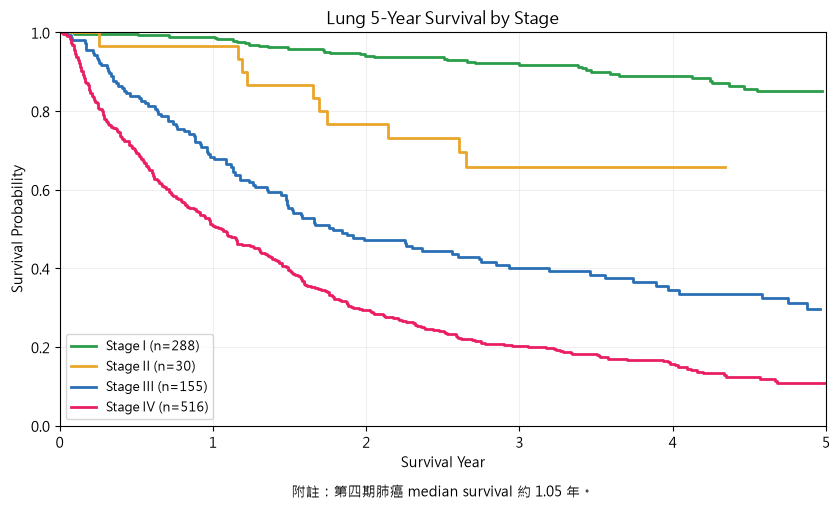


■ 結直腸癌 (Colon and Rectum)  診斷年 108-112  n=693


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,693,81.1,67.2,60.9,53.3,49.8,50.7
Stage I,104,89.4,86.5,81.4,80.3,78.8,80.2
Stage II,172,89.0,75.6,73.0,65.1,60.0,61.1
Stage III,215,88.4,75.8,67.4,57.0,51.5,53.5
Stage IV,181,59.1,36.5,27.7,20.0,19.0,19.2


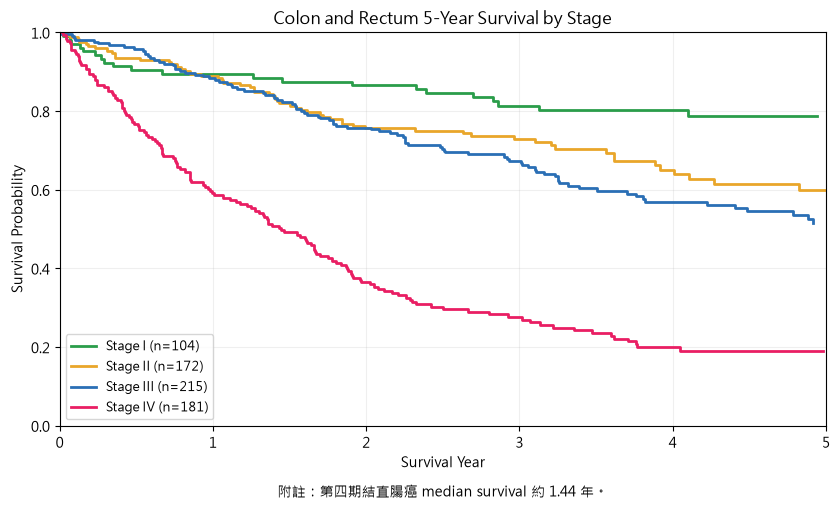


■ 攝護腺癌 (Prostate)  診斷年 108-112  n=647


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,647,95.1,89.2,83.0,76.8,71.2,73.0
Stage I,134,97.0,92.5,90.1,86.6,75.6,72.4
Stage II,168,98.2,94.0,87.2,84.7,82.4,81.9
Stage III,180,96.7,91.7,84.6,77.8,73.5,79.2
Stage IV,161,89.4,79.5,71.7,59.9,52.1,55.1


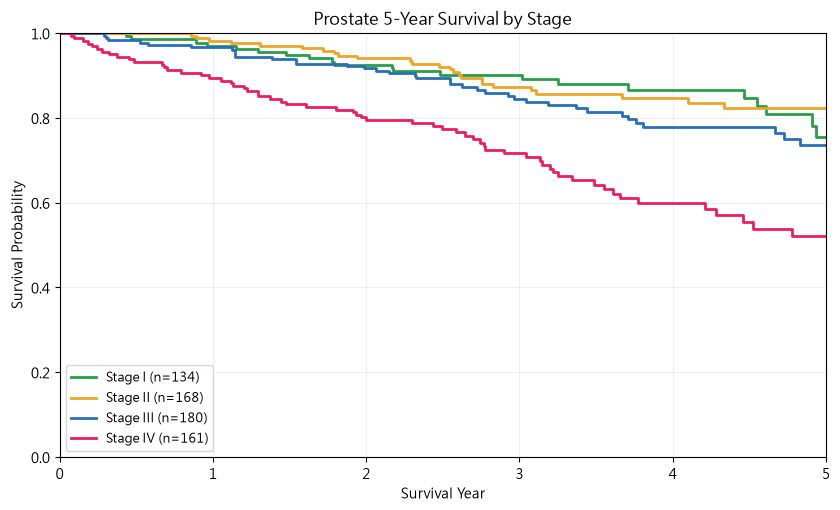


■ 肝癌 (Liver)  診斷年 108-112  n=543


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,543,69.6,56.9,50.6,44.8,39.3,40.2
Stage I,256,92.2,84.0,77.7,71.6,65.4,66.6
Stage II,89,88.8,69.7,60.2,50.5,37.7,37.6
Stage III,130,37.7,22.3,17.3,12.0,10.5,11.3
Stage IV,68,20.6,4.4,0.0,0.0,0.0,0.0


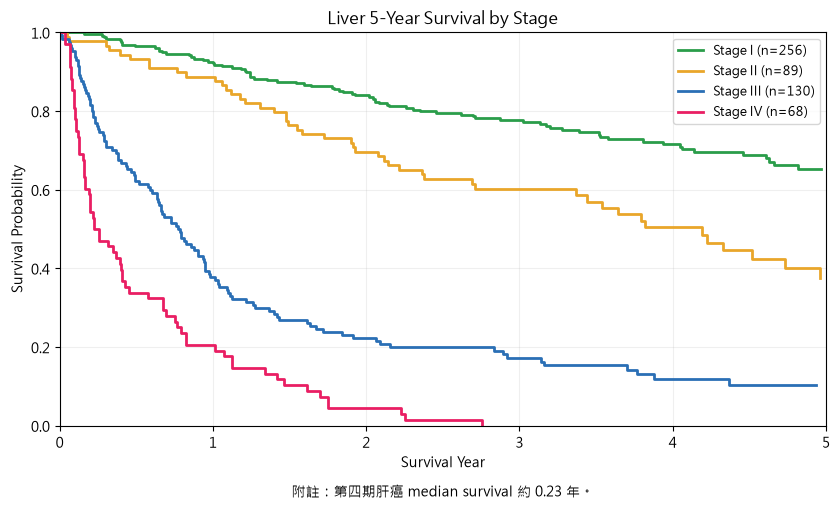


■ 乳癌 (Breast)  診斷年 108-112  n=502


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,502,96.6,93.8,90.3,87.5,85.4,87.7
Stage I,172,99.4,99.4,98.6,96.7,96.7,97.0
Stage II,210,98.6,96.7,94.9,92.2,89.8,92.3
Stage III,67,95.5,86.6,78.2,75.8,75.8,74.4
Stage IV,45,77.8,68.9,56.4,46.2,28.9,—


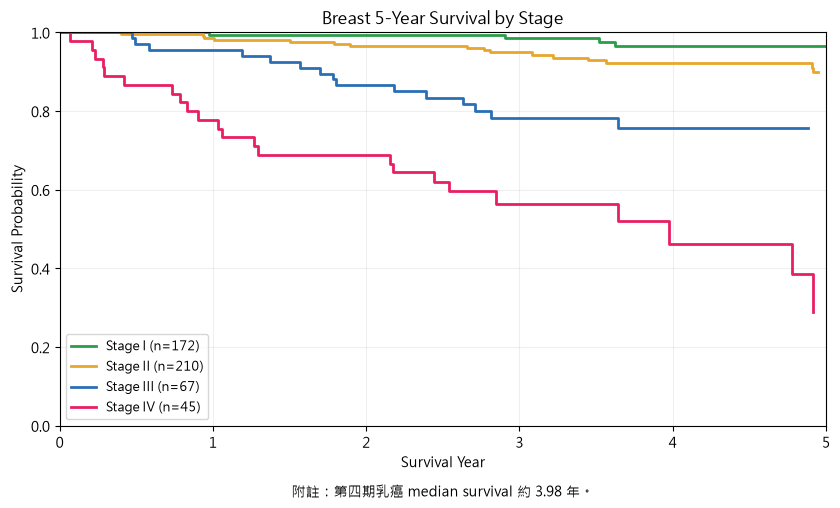


■ 口腔癌 (Oral cavity)  診斷年 108-112  n=443


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,443,86.0,74.3,67.1,62.2,57.6,62.0
Stage I,126,98.4,96.0,90.4,82.2,74.3,78.6
Stage II,77,92.2,79.2,69.3,69.3,69.3,73.5
Stage III,62,91.9,74.2,68.3,66.1,62.8,66.2
Stage IV,169,71.6,55.6,47.7,42.5,41.1,—
Stage IV M0,163,73.0,56.4,49.0,43.5,42.1,—
Stage IV M1,6,33.3,33.3,16.7,16.7,16.7,—


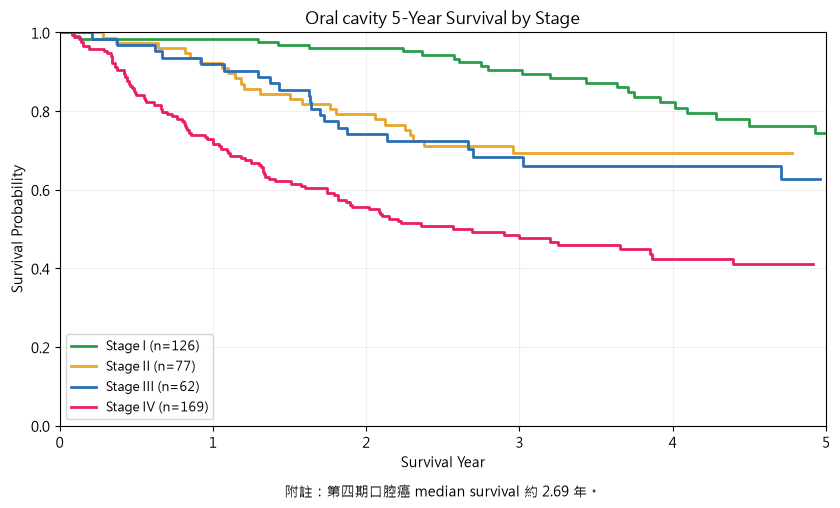


■ 食道癌 (Esophagus)  診斷年 108-112  n=142


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,142,56.3,37.3,29.2,21.5,21.5,23.2
Stage I,4,75.0,75.0,75.0,75.0,—,—
Stage II,20,75.0,70.0,59.2,40.0,40.0,—
Stage III,33,78.8,39.4,25.5,21.9,21.9,—
Stage IV,85,42.4,27.1,21.2,14.5,14.5,—


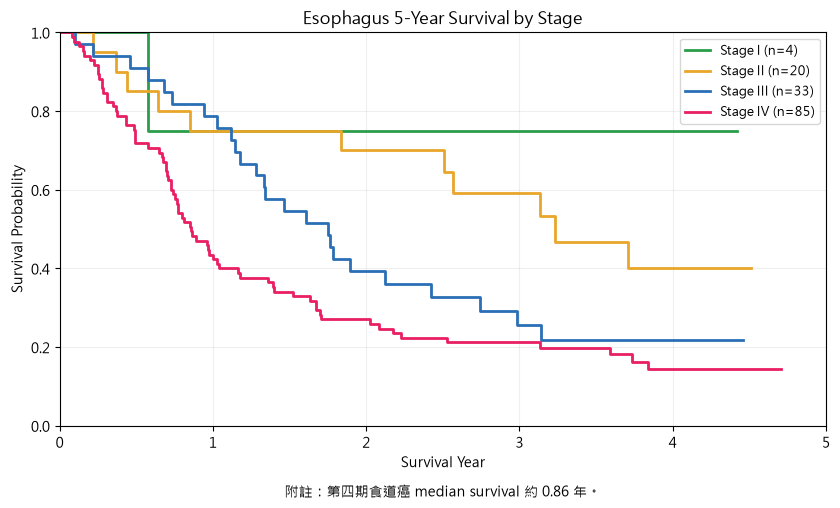


■ 子宮體癌 (Corpus)  診斷年 108-112  n=134


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,134,91.8,85.1,81.7,78.6,72.1,72.2
Stage I,100,97.0,92.0,90.7,89.2,82.4,81.0
Stage II,2,100.0,100.0,100.0,100.0,100.0,—
Stage III,17,88.2,82.4,76.5,61.8,61.8,—
Stage IV,13,53.8,30.8,15.4,15.4,—,—


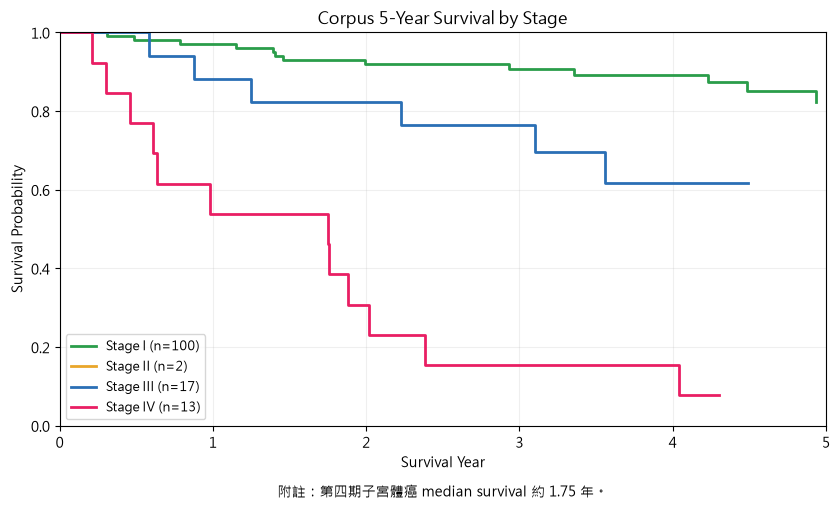


■ 口咽癌 (Oropharynx)  診斷年 108-112  n=124


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,124,79.8,58.9,52.6,50.6,44.0,46.5
Stage I,32,93.8,90.6,87.1,87.1,77.4,78.0
Stage II,18,94.4,66.7,61.1,61.1,48.9,—
Stage III,16,75.0,50.0,42.9,42.9,42.9,—
Stage IV,57,68.4,40.4,31.9,27.0,22.5,29.9
Stage IV M0,53,73.6,43.4,34.4,29.1,24.2,30.8
Stage IV M1,4,0.0,0.0,0.0,0.0,0.0,—


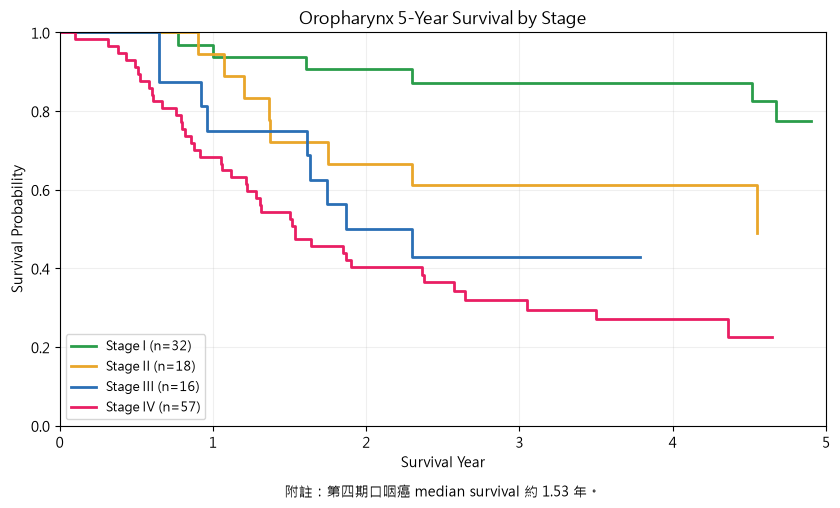


■ 胃癌 (Stomach)  診斷年 108-112  n=92


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,92,62.0,42.4,34.7,32.4,25.9,—
Stage I,19,89.5,84.2,84.2,84.2,56.1,—
Stage II,16,81.2,68.8,62.5,50.0,50.0,—
Stage III,24,58.3,41.7,28.1,28.1,—,—
Stage IV,32,37.5,6.2,0.0,0.0,0.0,0.0


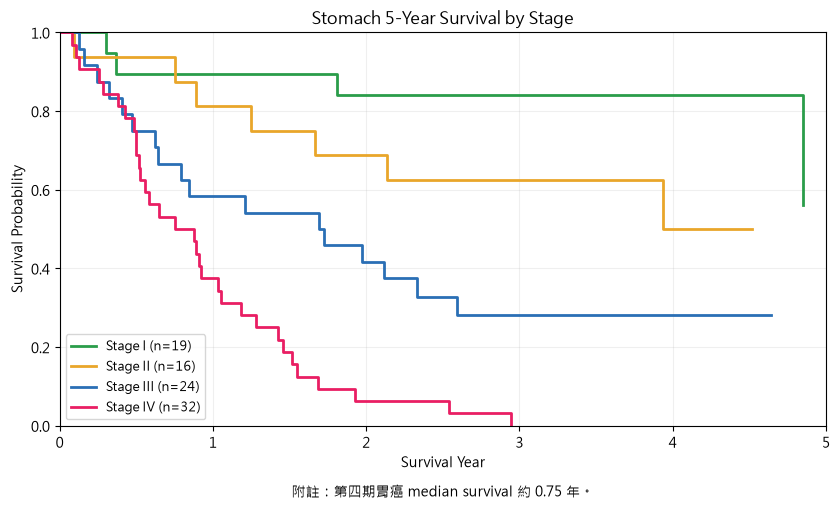


■ 膀胱癌 (Bladder)  診斷年 108-112  n=89


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,89,77.5,62.9,50.0,42.9,40.6,44.9
Stage I,45,88.9,77.8,63.9,56.1,56.1,59.7
Stage II,17,76.5,58.8,39.7,15.9,15.9,—
Stage III,25,60.0,40.0,31.5,31.5,31.5,31.3
Stage IV,2,50.0,50.0,50.0,50.0,0.0,—


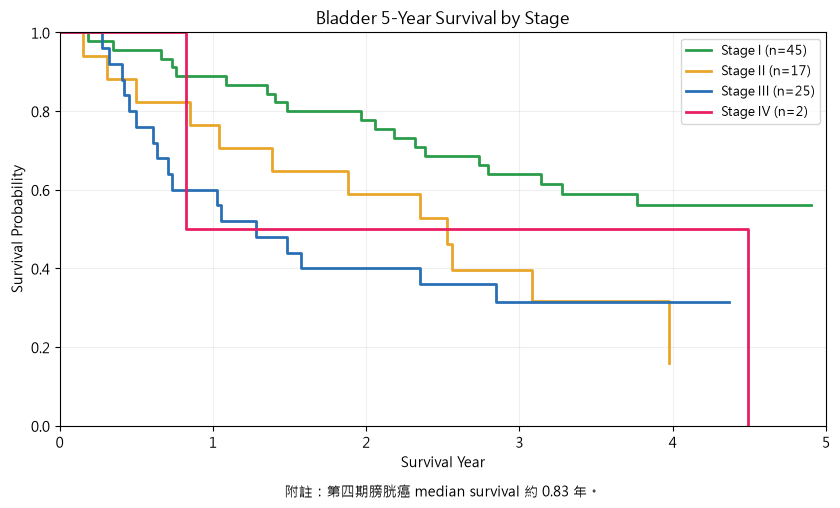


■ 下咽癌 (Hypopharynx)  診斷年 108-112  n=79


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,79,74.7,64.6,52.5,46.1,46.1,46.0
Stage I,5,100.0,100.0,75.0,75.0,75.0,—
Stage II,8,75.0,37.5,37.5,37.5,37.5,—
Stage III,3,100.0,100.0,100.0,66.7,—,—
Stage IV,63,71.4,63.5,50.5,44.5,44.5,45.0
Stage IV M0,57,73.7,68.4,55.8,49.1,49.1,48.8
Stage IV M1,6,50.0,16.7,0.0,0.0,0.0,—


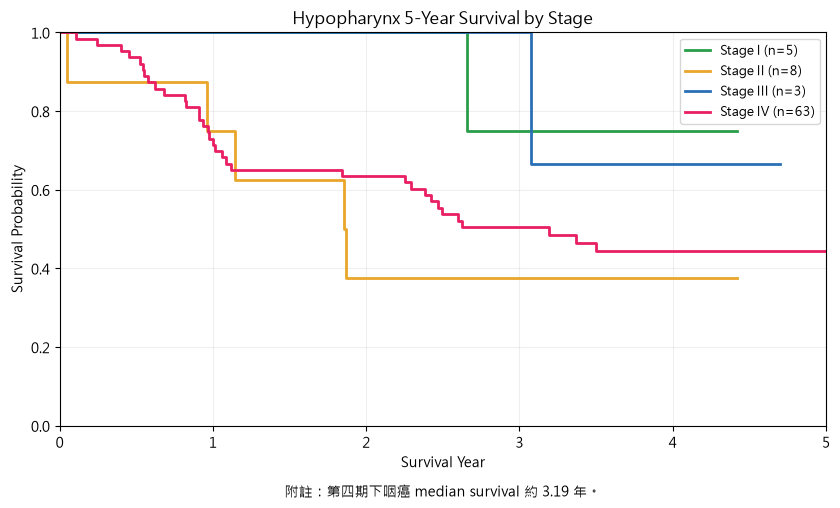


■ 鼻咽癌 (Nasopharynx)  診斷年 108-112  n=66


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,66,90.9,86.4,78.3,76.2,76.2,81.1
Stage I,4,100.0,100.0,100.0,100.0,100.0,—
Stage II,14,100.0,92.9,92.9,92.9,92.9,—
Stage III,25,92.0,92.0,83.8,77.8,77.8,—
Stage IV,23,82.6,73.9,59.0,59.0,59.0,—
Stage IV M0,18,83.3,77.8,59.6,59.6,59.6,—
Stage IV M1,5,80.0,60.0,60.0,60.0,—,—


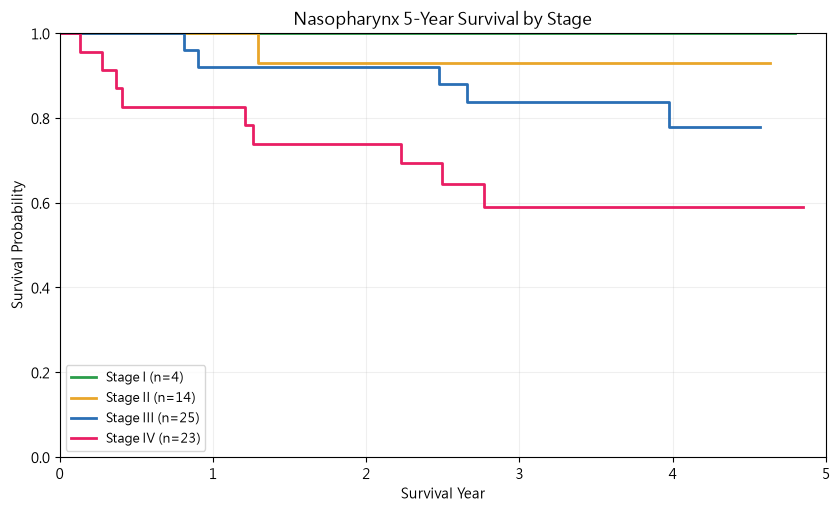


■ 胰臟癌 (Pancreas)  診斷年 111-112  n=50


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,50,40.0,16.0,3.5,0.0,0.0,—
Stage I,7,85.7,57.1,0.0,0.0,0.0,—
Stage II,8,62.5,25.0,25.0,0.0,0.0,—
Stage III,9,66.7,22.2,0.0,0.0,0.0,—
Stage IV,26,11.5,0.0,0.0,0.0,0.0,0.0


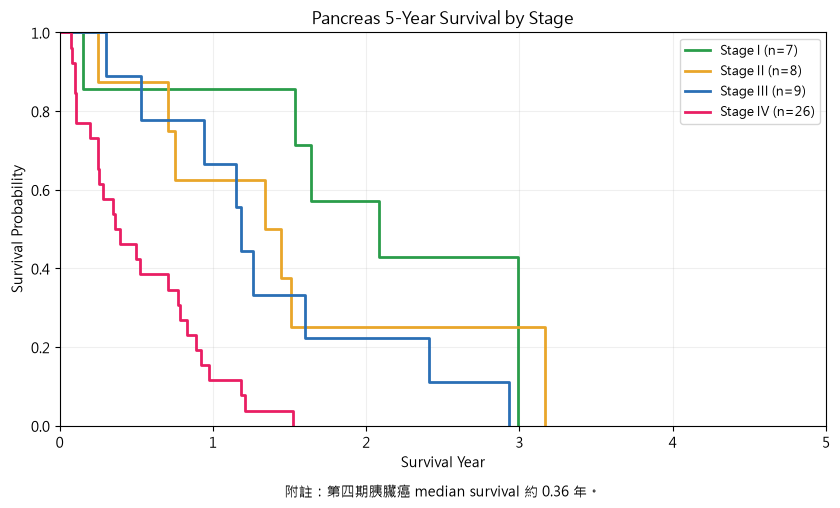


■ 喉癌 (Larynx)  診斷年 108-112  n=47


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,47,83.0,70.2,58.5,48.9,45.4,50.7
Stage I,16,93.8,87.5,71.8,71.8,71.8,—
Stage II,7,100.0,71.4,42.9,21.4,21.4,—
Stage III,5,80.0,80.0,53.3,53.3,—,—
Stage IV,19,68.4,52.6,52.6,40.9,35.1,—
Stage IV M0,16,81.2,62.5,62.5,48.6,41.7,—
Stage IV M1,3,0.0,0.0,0.0,0.0,0.0,—


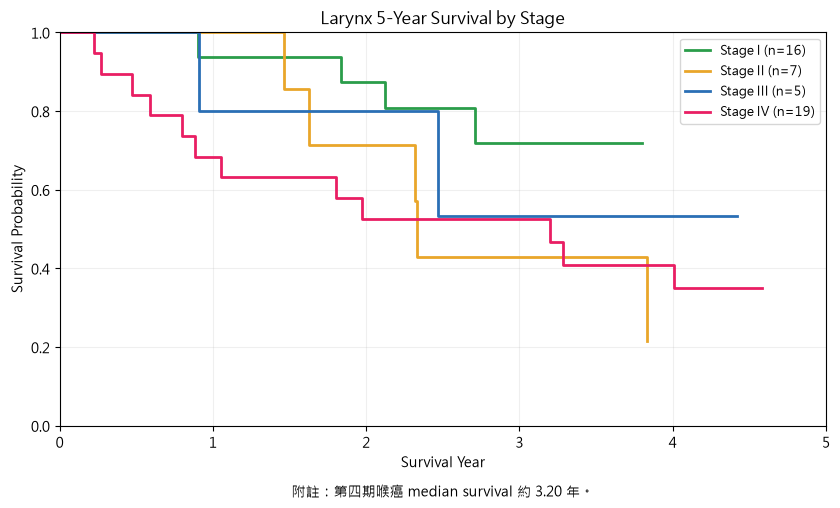


■ 子宮頸癌 (Cervix)  診斷年 110-112  n=40


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,40,85.0,75.0,64.5,64.5,—,—
Stage I,13,84.6,76.9,76.9,76.9,—,—
Stage II,9,88.9,77.8,77.8,77.8,—,—
Stage III,9,88.9,77.8,62.2,—,—,—
Stage IV,9,77.8,66.7,26.7,26.7,—,—


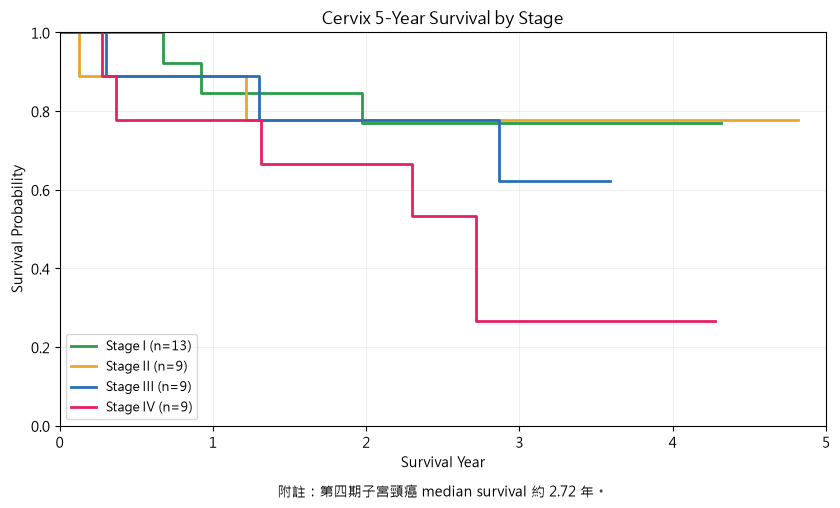


■ 卵巢癌 (Ovary)  診斷年 108-112  n=36


AJCC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,36,94.4,86.1,68.7,65.3,65.3,68.7
Stage I,12,100.0,100.0,100.0,100.0,100.0,—
Stage II,2,100.0,100.0,50.0,50.0,50.0,—
Stage III,16,100.0,81.2,54.7,43.8,43.8,—
Stage IV,5,60.0,60.0,40.0,40.0,40.0,—


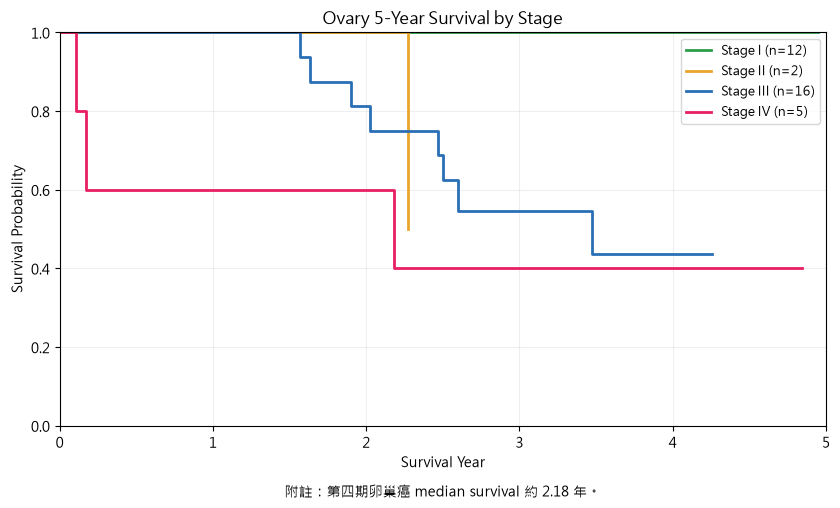

In [8]:
YR_COLS = ['1-yr','2-yr','3-yr','4-yr','5-yr','加權5年%']
for cname in summary.index:
    if summary.loc[cname, '個案數'] < 5: continue
    y0, y1 = year_range(cname)
    print(f'\n■ {NAME_ZH.get(cname, cname)} ({cname})  診斷年 {y0}-{y1}  n={int(summary.loc[cname,"個案數"])}')
    styler = (survival_table(cname).style
              .format({c: '{:.1f}' for c in YR_COLS}, na_rep='—')
              .set_caption('Observed Survival (%)；加權5年%=官方權重年齡標準化')
              .set_table_styles([
                  {'selector':'caption','props':'font-weight:bold; font-size:13px; text-align:center;'},
                  {'selector':'th','props':'background:#e8e8e8; text-align:center; border:1px solid #888;'},
                  {'selector':'td','props':'text-align:center; border:1px solid #888;'},
                  {'selector':'table','props':'border-collapse:collapse;'}])
              .apply(lambda r: ['font-weight:bold; font-style:italic;' if r['AJCC Stage']=='All' else '' for _ in r], axis=1)
              .hide(axis='index'))
    display(styler)
    plot_km(cname)

## 三、FIGO / BCLC 額外分期（AJCC 之外另外提供）

依 Word：肝癌另提供 **BCLC**（0/A/B/C/D），子宮頸/子宮體/卵巢另提供 **FIGO**（I–IV）。
分期取自資料 `fnostage` 欄首字；診斷年一律 **108-112**（子宮頸 FIGO 採 108-112，與其 AJCC 110-112 不同）；
`999/8888` 視為不詳（計入 All、不計入各期）。KM 不外推、年齡標準化沿用同一套官方權重與併組規則。


◆ 肝癌 (Liver) — BCLC 分期  診斷年 108-112  n=543


BCLC Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,543,69.6,56.9,50.6,44.8,39.3,40.2
BCLC 0,77,97.4,93.5,89.4,82.6,77.3,75.6
BCLC A,179,94.4,82.7,73.8,65.9,56.7,57.3
BCLC B,95,75.8,60.0,55.1,45.7,39.8,41.8
BCLC C,147,38.1,20.4,13.3,11.6,9.1,9.3
BCLC D,45,13.3,4.4,4.4,0.0,0.0,—


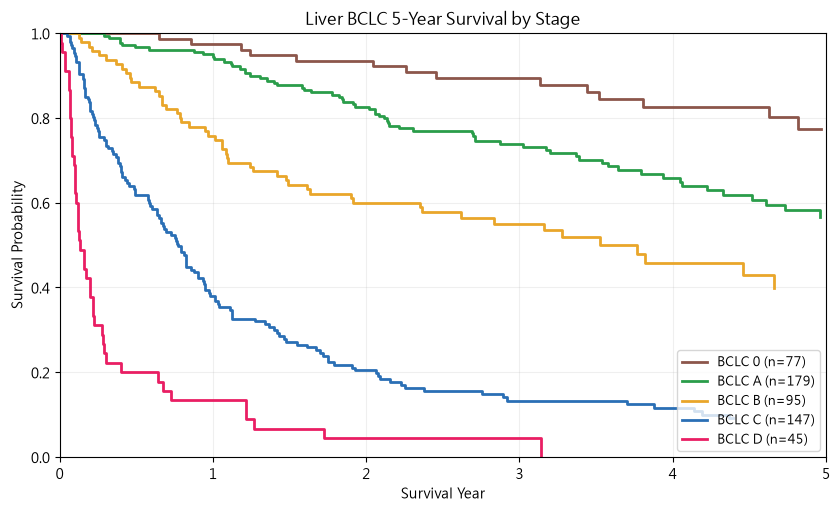


◆ 子宮頸癌 (Cervix) — FIGO 分期  診斷年 108-112  n=60


FIGO Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,60,86.7,70.0,58.3,58.3,58.3,63.7
Stage I,17,88.2,82.4,82.4,82.4,82.4,—
Stage II,10,90.0,80.0,68.6,68.6,—,—
Stage III,14,85.7,71.4,54.4,54.4,54.4,—
Stage IV,16,81.2,50.0,23.8,23.8,23.8,—


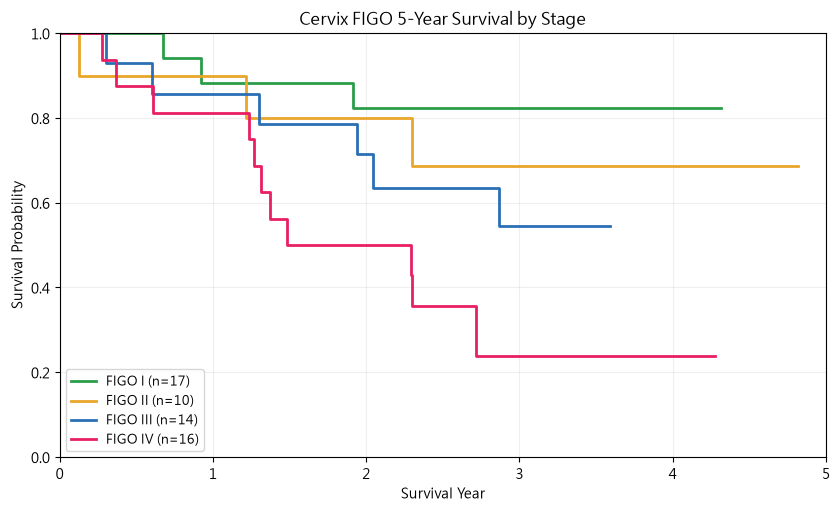


◆ 子宮體癌 (Corpus) — FIGO 分期  診斷年 108-112  n=134


FIGO Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,134,91.8,85.1,81.7,78.6,72.1,72.2
Stage I,94,96.8,92.6,91.2,89.6,85.4,85.8
Stage II,2,100.0,100.0,100.0,100.0,100.0,—
Stage III,14,92.9,85.7,85.7,76.2,76.2,—
Stage IV,9,55.6,33.3,22.2,22.2,—,—


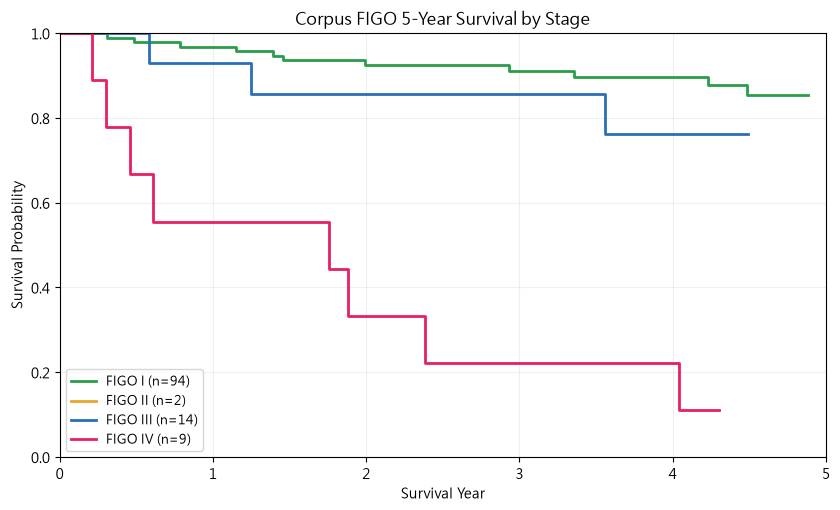


◆ 卵巢癌 (Ovary) — FIGO 分期  診斷年 108-112  n=36


FIGO Stage,(Case No.),1-yr,2-yr,3-yr,4-yr,5-yr,加權5年%
All,36,94.4,86.1,68.7,65.3,65.3,68.7
Stage I,13,100.0,100.0,92.3,92.3,92.3,—
Stage II,2,100.0,100.0,50.0,50.0,50.0,—
Stage III,12,100.0,83.3,64.3,51.4,51.4,—
Stage IV,2,50.0,50.0,50.0,50.0,—,—


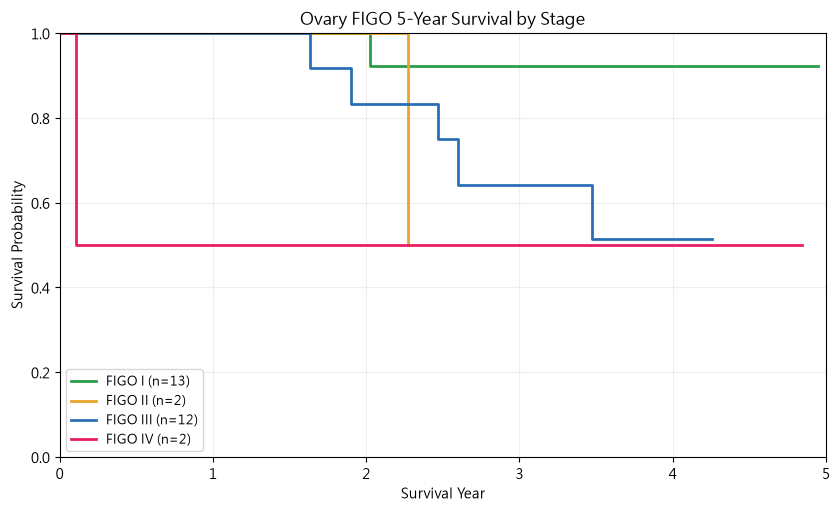

In [9]:
### FIGO / BCLC 額外分期
ALT_SYS = {'Liver':'BCLC','Cervix':'FIGO','Corpus':'FIGO','Ovary':'FIGO'}

def alt_broad(cancer, code):
    s = str(code).strip().upper()
    if not s or s in ('999','8888','NAN'):
        return None
    if ALT_SYS[cancer] == 'BCLC':
        return s[0] if s[0] in '0ABCD' else None
    return {'1':'I','2':'II','3':'III','4':'IV'}.get(s[0])

# 這四癌別 FIGO/BCLC 一律診斷年 108-112
alt = raw[raw['cancer'].isin(ALT_SYS) & raw['year'].between(108,112)].dropna(subset=['t_months','event']).copy()
alt['alt_stage'] = alt.apply(lambda r: alt_broad(r['cancer'], r['fnostage']), axis=1)

def alt_stages_for(cancer):
    if ALT_SYS[cancer] == 'BCLC':
        return [('All','ALL'),('BCLC 0','0'),('BCLC A','A'),('BCLC B','B'),('BCLC C','C'),('BCLC D','D')]
    return [('All','ALL'),('Stage I','I'),('Stage II','II'),('Stage III','III'),('Stage IV','IV')]

def alt_survival_table(cname):
    whole = alt[alt['cancer'] == cname]
    rows = []
    for lbl, key in alt_stages_for(cname):
        g = whole if key == 'ALL' else whole[whole['alt_stage'] == key]
        row = {f'{ALT_SYS[cname]} Stage': lbl, '(Case No.)': len(g)}
        for yr in [1,2,3,4,5]:
            s = S_at(g['t_months'], g['event'], yr*12) if len(g) else np.nan
            row[f'{yr}-yr'] = np.nan if (not len(g) or pd.isna(s)) else round(s*100, 1)
        wa = weighted_S(cname, g, 60) if len(g) else np.nan
        row['加權5年%'] = np.nan if pd.isna(wa) else round(wa, 1)
        rows.append(row)
    return pd.DataFrame(rows)

ALT_COLORS = {'BCLC':[('0','#8c564b'),('A','#2a9d4a'),('B','#e9a62a'),('C','#2a6fb5'),('D','#e91e63')],
              'FIGO':[('I','#2a9d4a'),('II','#e9a62a'),('III','#2a6fb5'),('IV','#e91e63')]}

def alt_plot_km(cname):
    whole = alt[alt['cancer'] == cname]; sysname = ALT_SYS[cname]
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    for key, color in ALT_COLORS[sysname]:
        g = whole[whole['alt_stage'] == key]
        if len(g) == 0: continue
        km_t, km_S = km_curve(g['t_months'], g['event'])
        yr = km_t/12.0; mask = yr <= 5
        ax.step(yr[mask], km_S[mask], where='post', color=color, linewidth=2, label=f'{sysname} {key} (n={len(g)})')
    ax.set_xlim(0,5); ax.set_ylim(0,1.0); ax.set_xticks([0,1,2,3,4,5])
    ax.set_xlabel('Survival Year'); ax.set_ylabel('Survival Probability')
    ax.set_title(f'{cname} {sysname} 5-Year Survival by Stage')
    ax.grid(True, alpha=0.2); ax.legend(loc='best', fontsize=9)
    plt.tight_layout(); plt.show()

for cname in ['Liver','Cervix','Corpus','Ovary']:
    sysname = ALT_SYS[cname]; n = len(alt[alt['cancer']==cname])
    print('\n' + f'◆ {NAME_ZH.get(cname,cname)} ({cname}) — {sysname} 分期  診斷年 108-112  n={n}')
    styler = (alt_survival_table(cname).style
              .format({c:'{:.1f}' for c in YR_COLS}, na_rep='—')
              .set_caption(f'{sysname} Observed Survival (%)；加權5年%=官方權重年齡標準化')
              .set_table_styles([
                  {'selector':'caption','props':'font-weight:bold; font-size:13px; text-align:center;'},
                  {'selector':'th','props':'background:#e8e8e8; text-align:center; border:1px solid #888;'},
                  {'selector':'td','props':'text-align:center; border:1px solid #888;'},
                  {'selector':'table','props':'border-collapse:collapse;'}])
              .apply(lambda r: ['font-weight:bold; font-style:italic;' if r.iloc[0]=='All' else '' for _ in r], axis=1)
              .hide(axis='index'))
    display(styler)
    alt_plot_km(cname)